# Explanations

SHAP and LIME sit on the saved pipelines. Re-running this notebook does not change the hold-out scores. Local plots are produced for all three models; the cases themselves are chosen from XGBoost.


In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd().resolve()
if not (ROOT / "prep.py").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import json

import pandas as pd
from IPython.display import Image, display

from explain import run_explain
from prep import ROOT

WP3 = ROOT / "artefacts" / "wp3"
WP4 = ROOT / "artefacts" / "wp4"


In [2]:

metrics = json.loads((WP3 / "metrics.json").read_text(encoding="utf-8"))
rows = []
for name, block in metrics["models"].items():
    holdout = block["holdout"]
    rows.append({
        "model": name,
        "accuracy": holdout["accuracy"],
        "macro_f1": holdout["macro_f1"],
        "ovr_roc_auc": holdout["ovr_roc_auc_macro"],
        "binary_gini": holdout["binary_gini"],
    })
perf = pd.DataFrame(rows).sort_values("macro_f1", ascending=False)
display(perf.style.format("{:.3f}", subset=["accuracy", "macro_f1", "ovr_roc_auc", "binary_gini"]))
print("Best model:", (WP3 / "best_model.txt").read_text(encoding="utf-8").strip())


,model,accuracy,macro_f1,ovr_roc_auc,binary_gini
2,xgboost,0.528,0.430,0.841,0.617
1,random_forest,0.516,0.413,0.832,0.559
0,logistic_regression,0.432,0.338,0.802,0.545


Best model: xgboost


In [3]:

FORCE_RERUN = False
needed = [
    WP4 / "xgb_shap_global_bar.png",
    WP4 / "explanation_cases.json",
    WP4 / "lime_cases.json",
]
if FORCE_RERUN or not all(path.exists() for path in needed):
    result = run_explain()
    print("Wrote", result["out_dir"])
else:
    print("Using", WP4.relative_to(ROOT).as_posix())


Using artefacts/wp4


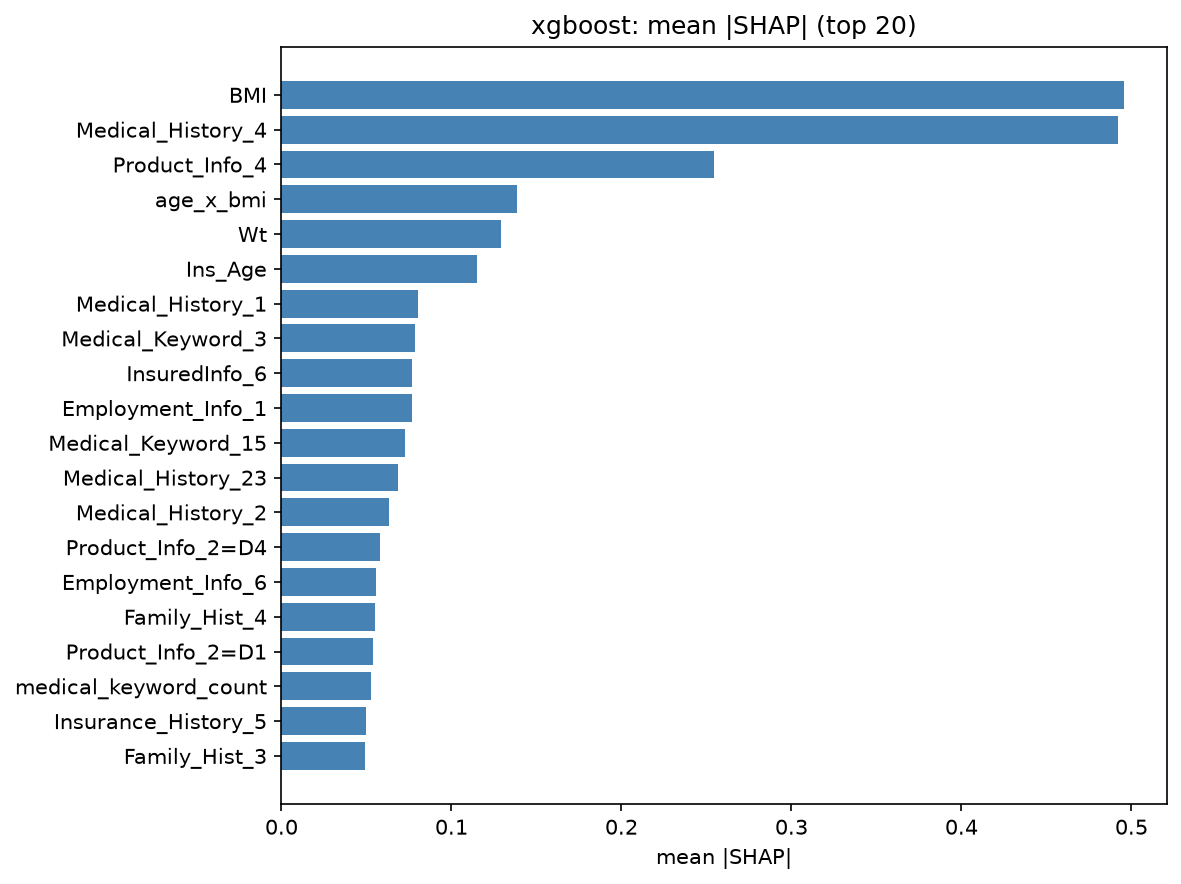

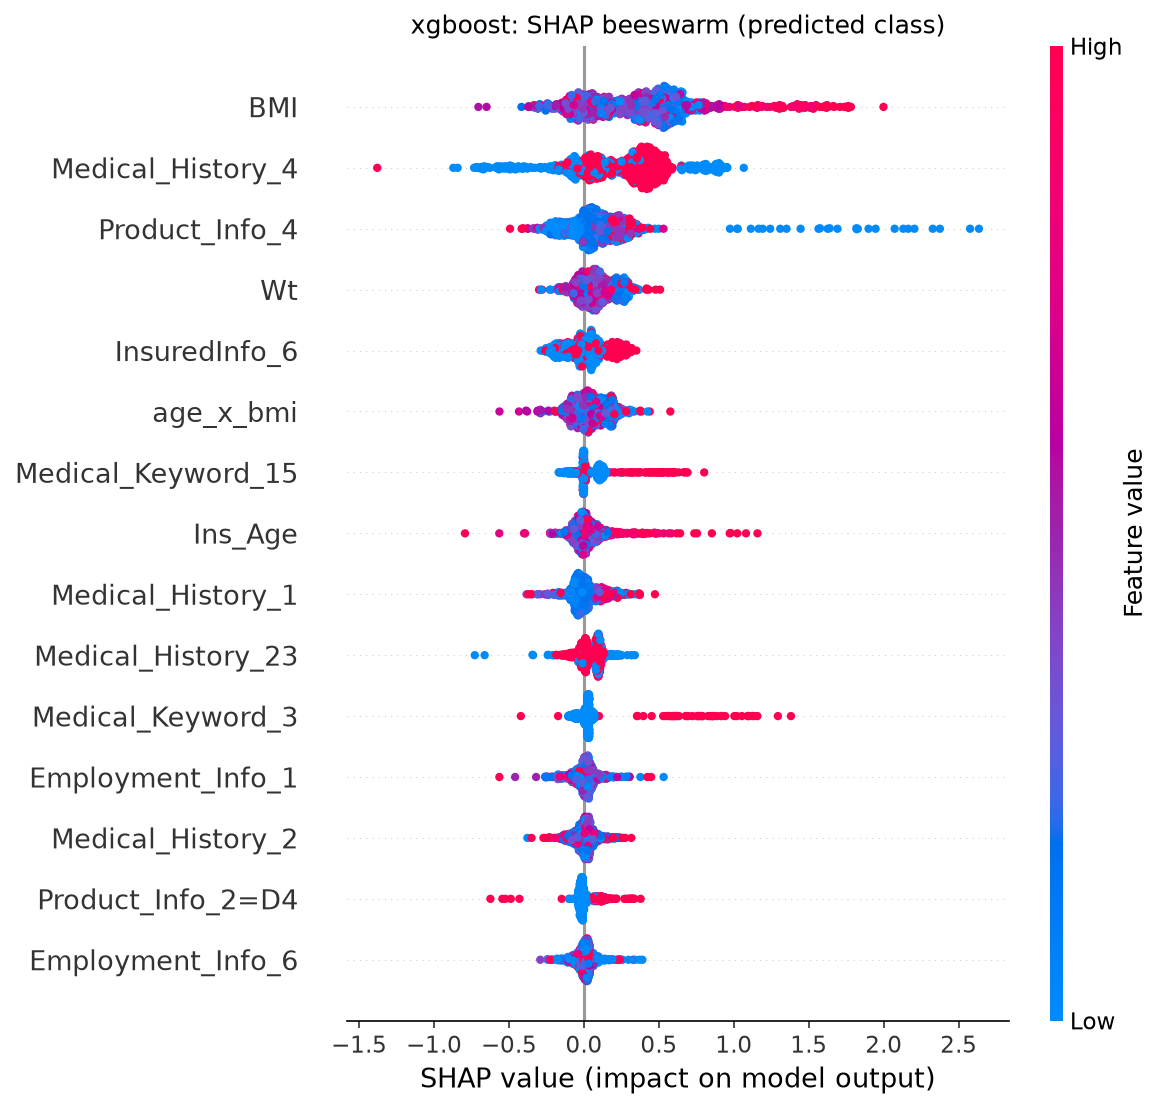

,feature,mean_abs_shap
0,BMI,0.495832
1,Medical_History_4,0.492257
2,Product_Info_4,0.254159
3,age_x_bmi,0.138821
4,Wt,0.128845
5,Ins_Age,0.114839
6,Medical_History_1,0.080222
7,Medical_Keyword_3,0.078746
8,InsuredInfo_6,0.077043
9,Employment_Info_1,0.076784


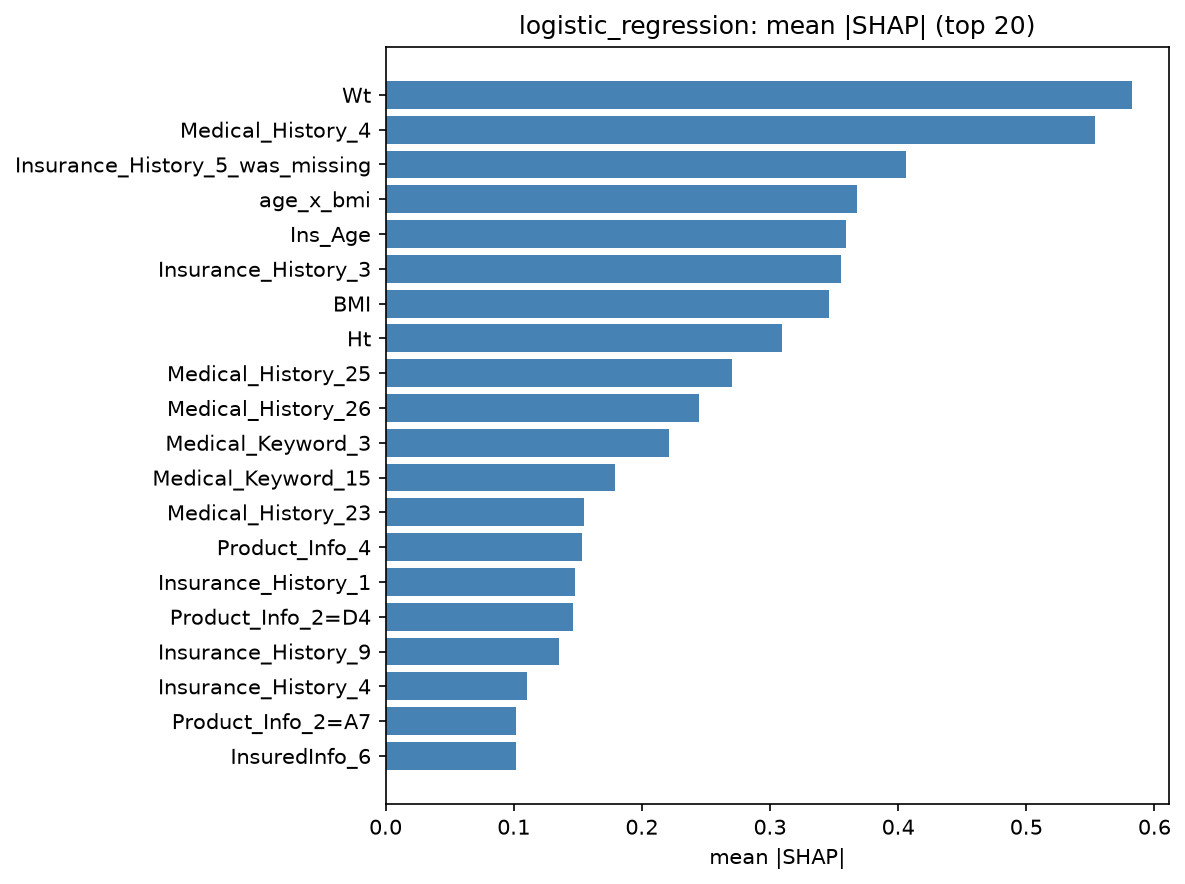

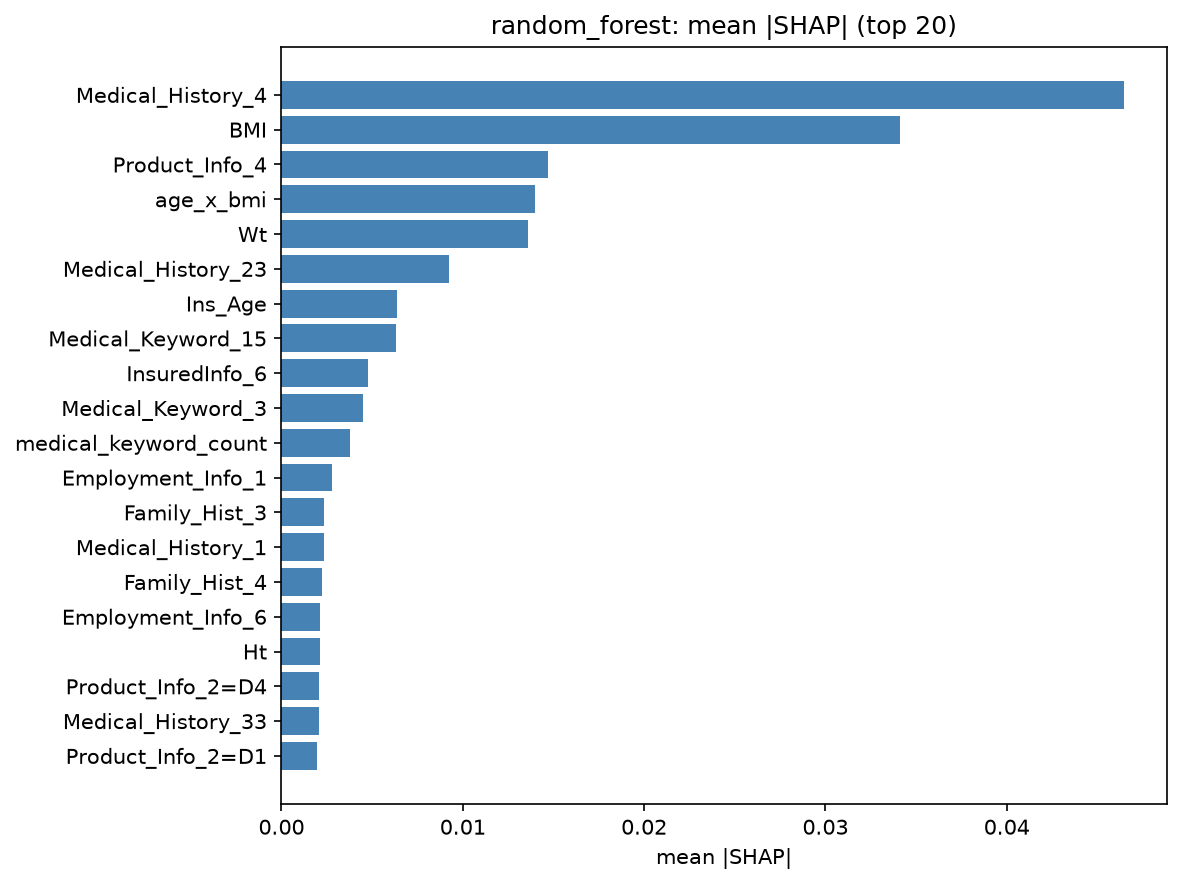

In [4]:

display(Image(filename=str(WP4 / "xgb_shap_global_bar.png")))
display(Image(filename=str(WP4 / "xgb_shap_summary.png")))
display(pd.read_json(WP4 / "xgb_top_features.json"))
display(Image(filename=str(WP4 / "lr_shap_global_bar.png")))
display(Image(filename=str(WP4 / "rf_shap_global_bar.png")))


,label,index,Id,y_true,y_pred,p_high
0,correct_high_risk,366,53825,8,8,0.989740
1,correct_low_risk,25,74347,1,1,0.000869
2,misclassified_high_to_low,10546,52233,7,2,0.654028
3,misclassified_low_to_high,3924,78960,3,5,0.293895
4,rare_class_3_or_4,1074,47820,4,4,0.208118
5,typical_class_8,5823,75307,8,8,0.989564


correct_high_risk | Id=53825 | true=8 pred=8


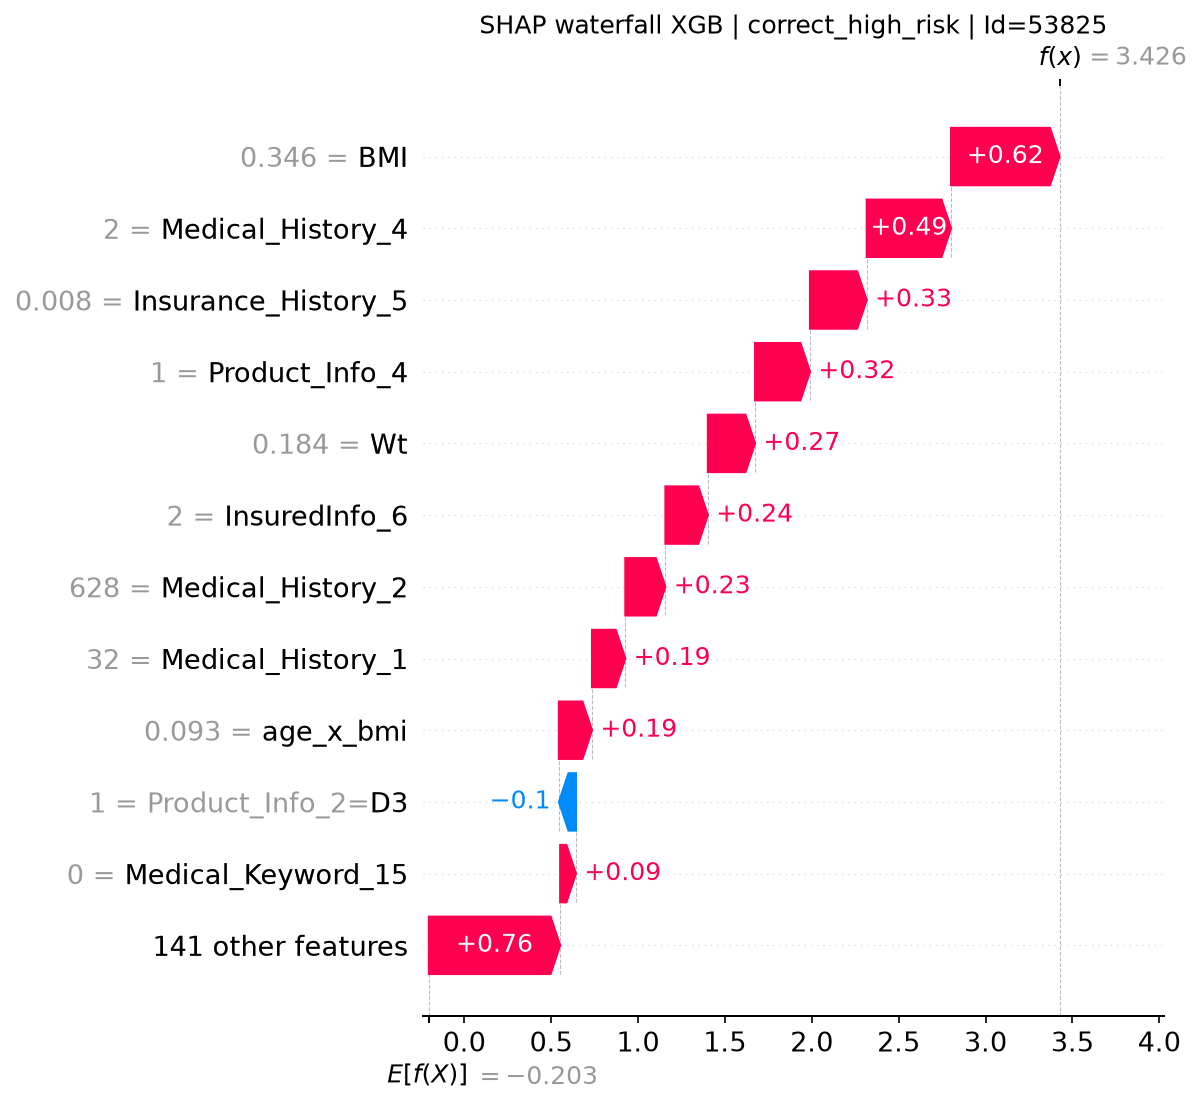

correct_low_risk | Id=74347 | true=1 pred=1


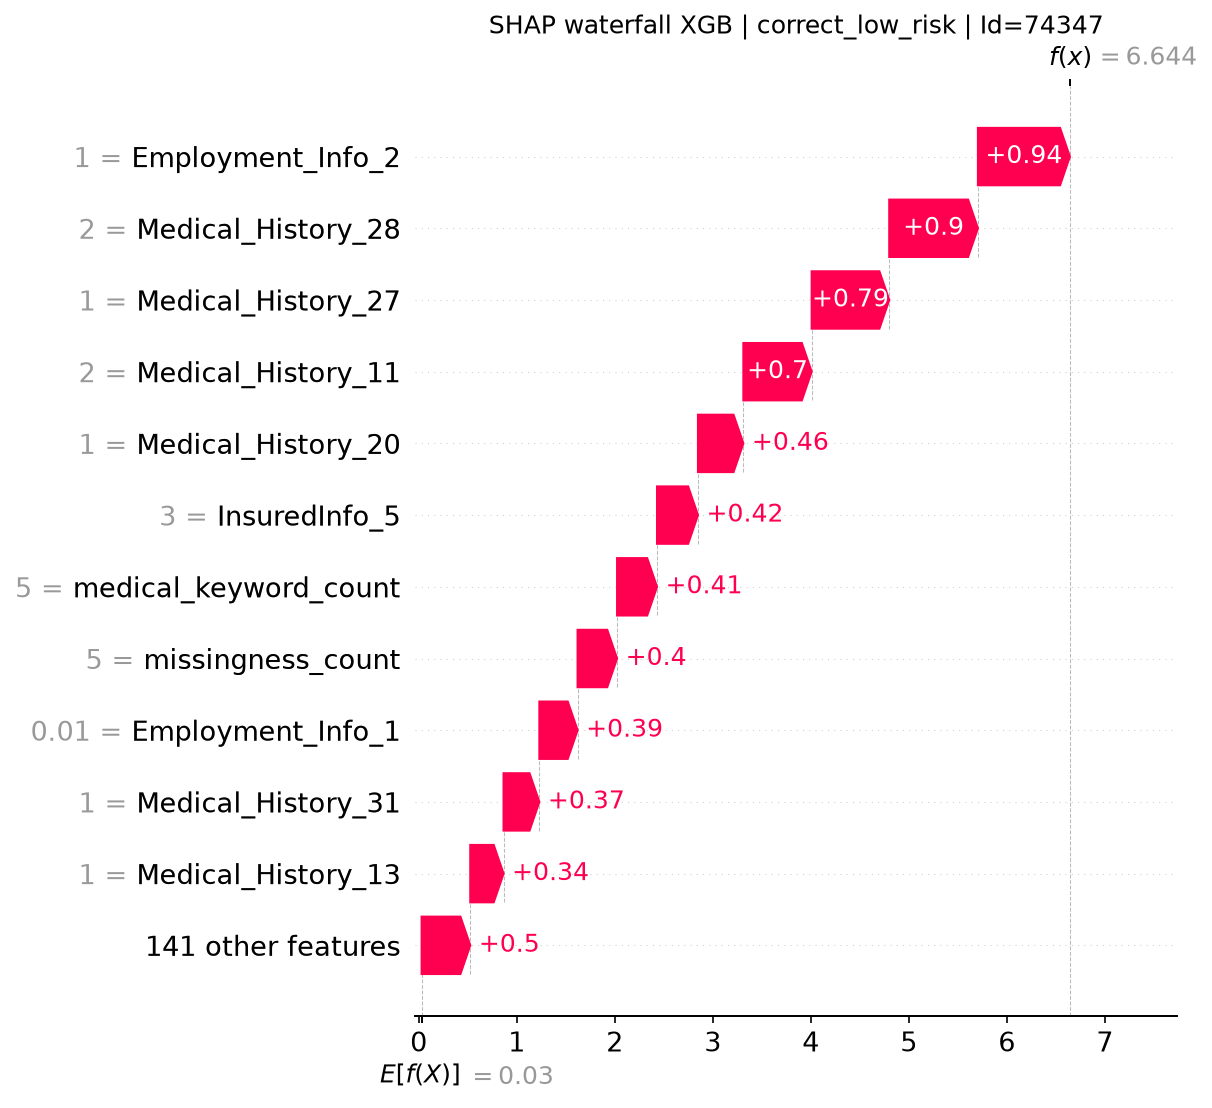

misclassified_high_to_low | Id=52233 | true=7 pred=2


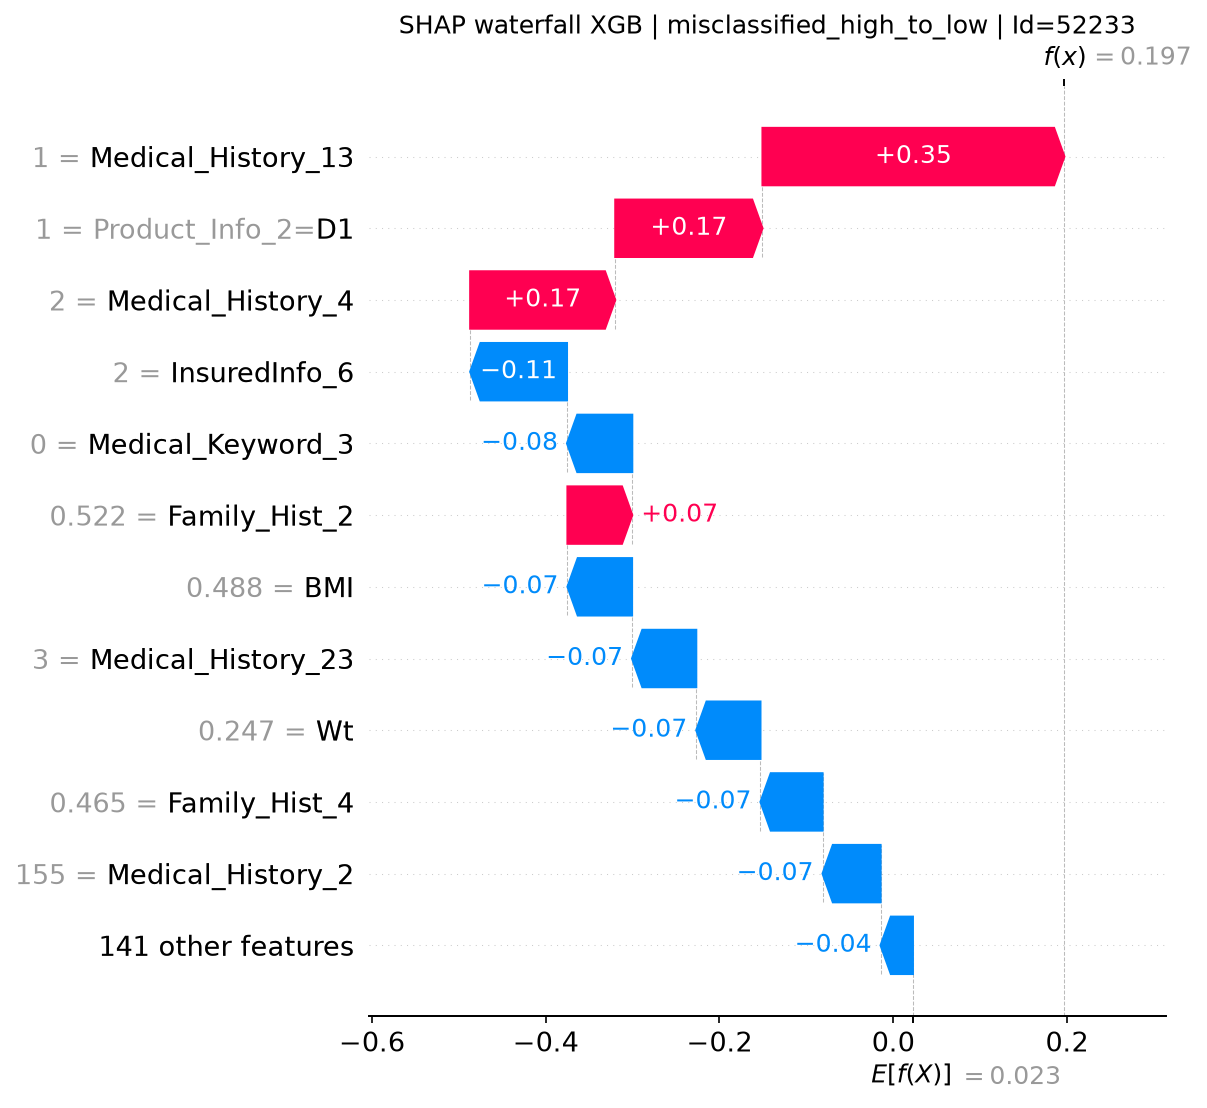

misclassified_low_to_high | Id=78960 | true=3 pred=5


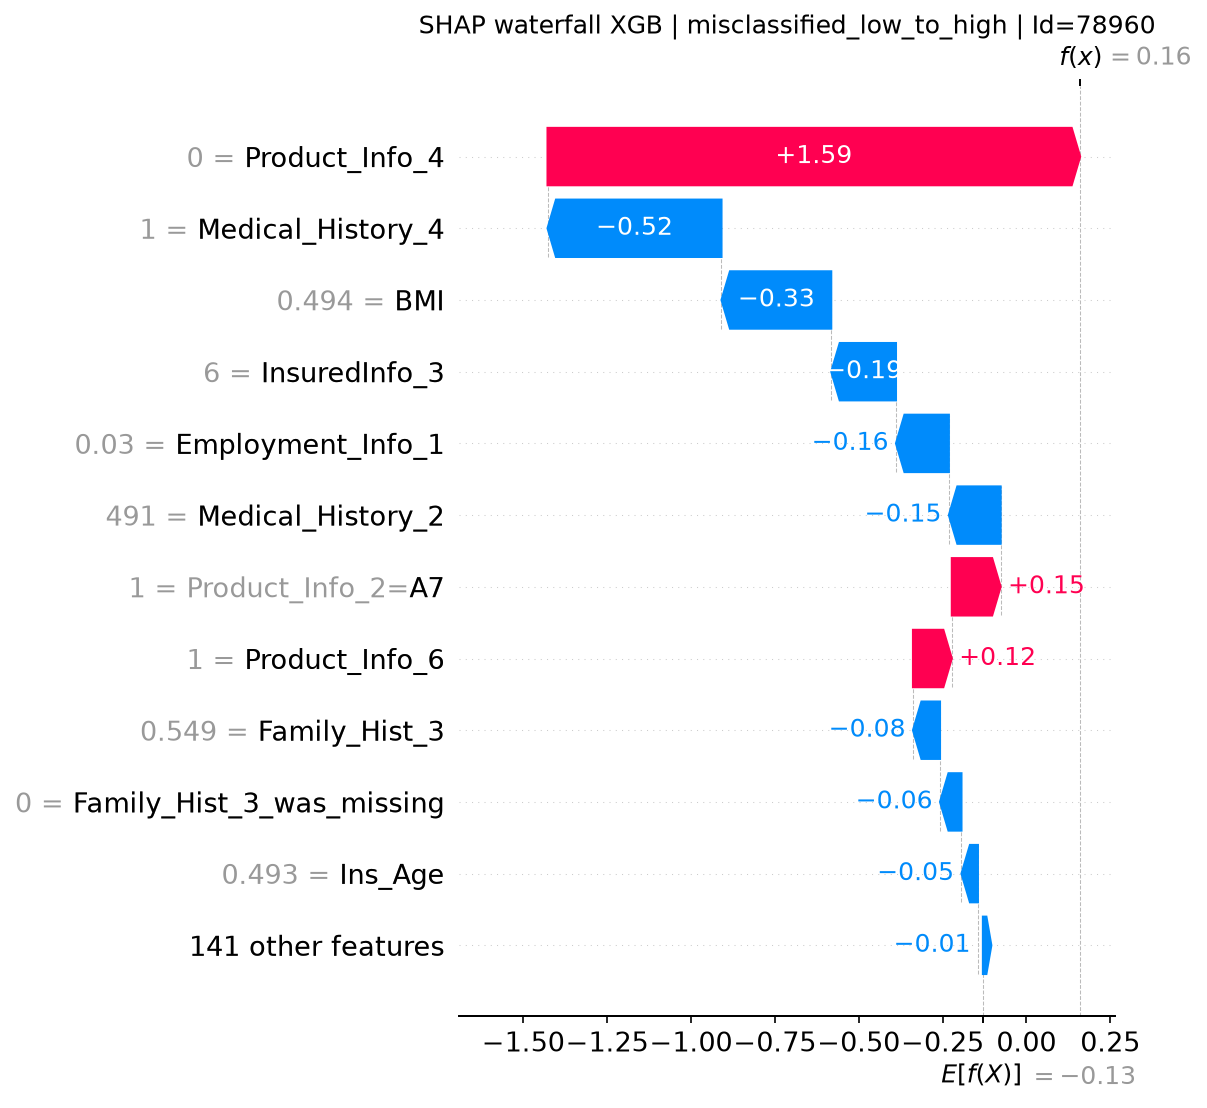

rare_class_3_or_4 | Id=47820 | true=4 pred=4


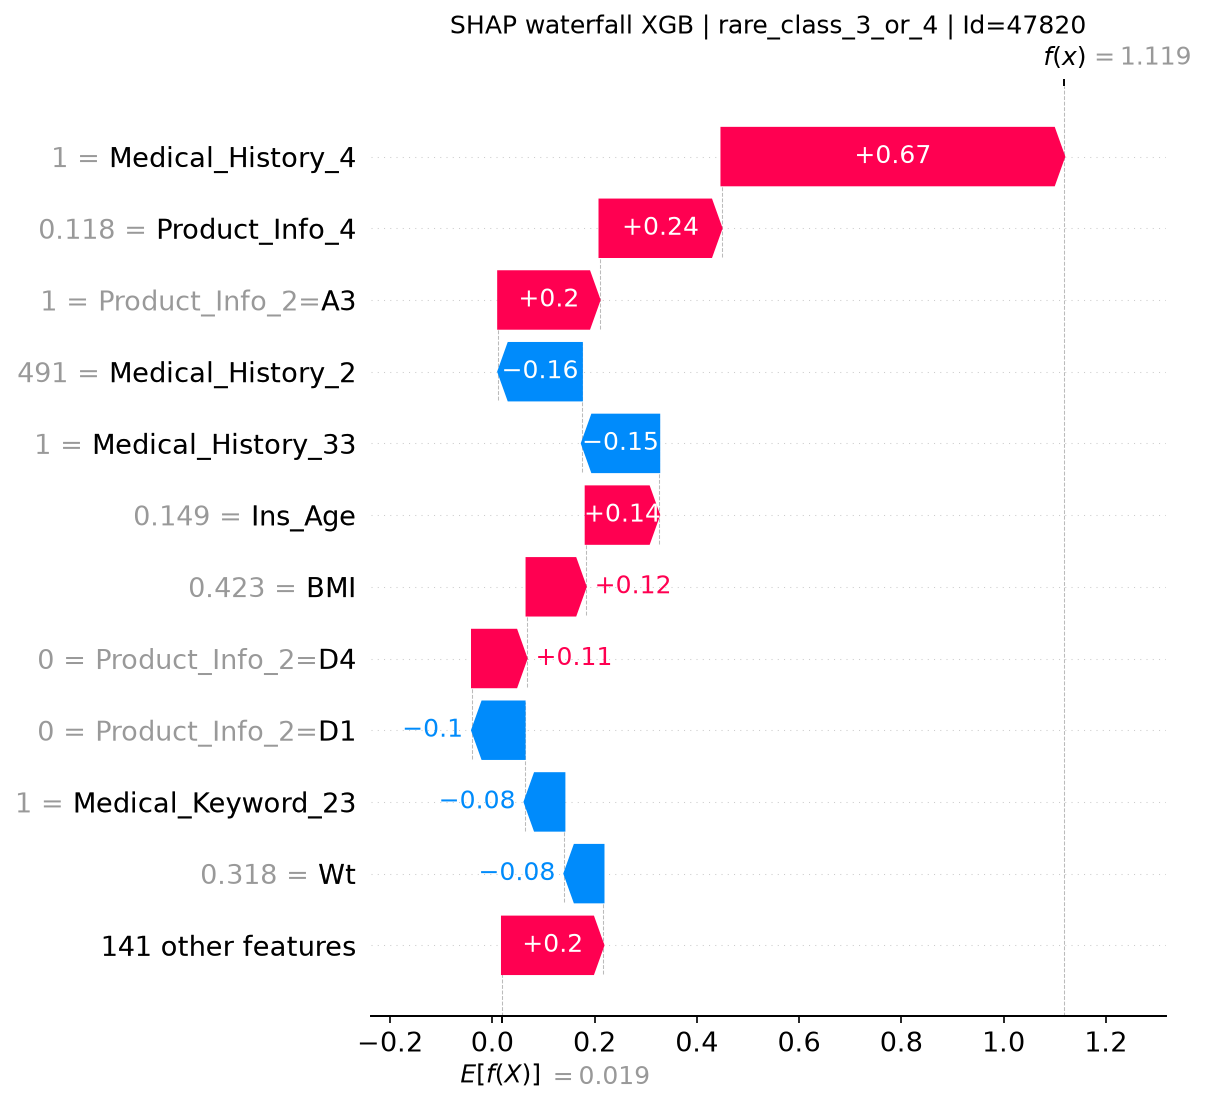

typical_class_8 | Id=75307 | true=8 pred=8


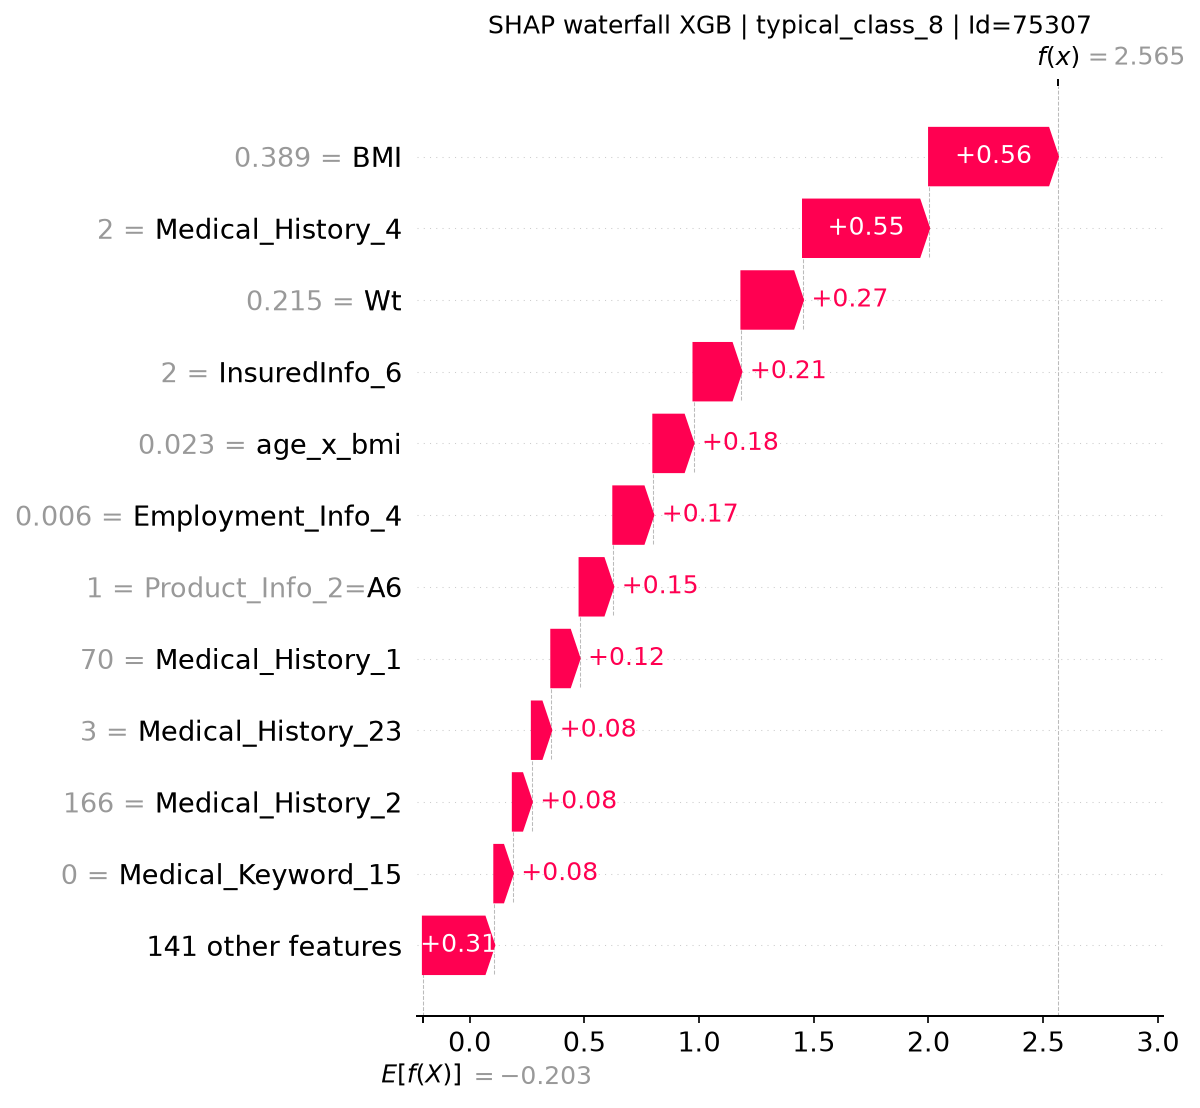

In [5]:

cases = json.loads((WP4 / "explanation_cases.json").read_text(encoding="utf-8"))["cases"]
display(pd.DataFrame(cases))
for i, case in enumerate(cases):
    print(f"{case['label']} | Id={case['Id']} | true={case['y_true']} pred={case['y_pred']}")
    display(Image(filename=str(WP4 / f"xgb_shap_waterfall_case{i}.png")))


xgboost | case 0 (correct_high_risk) | pred=8


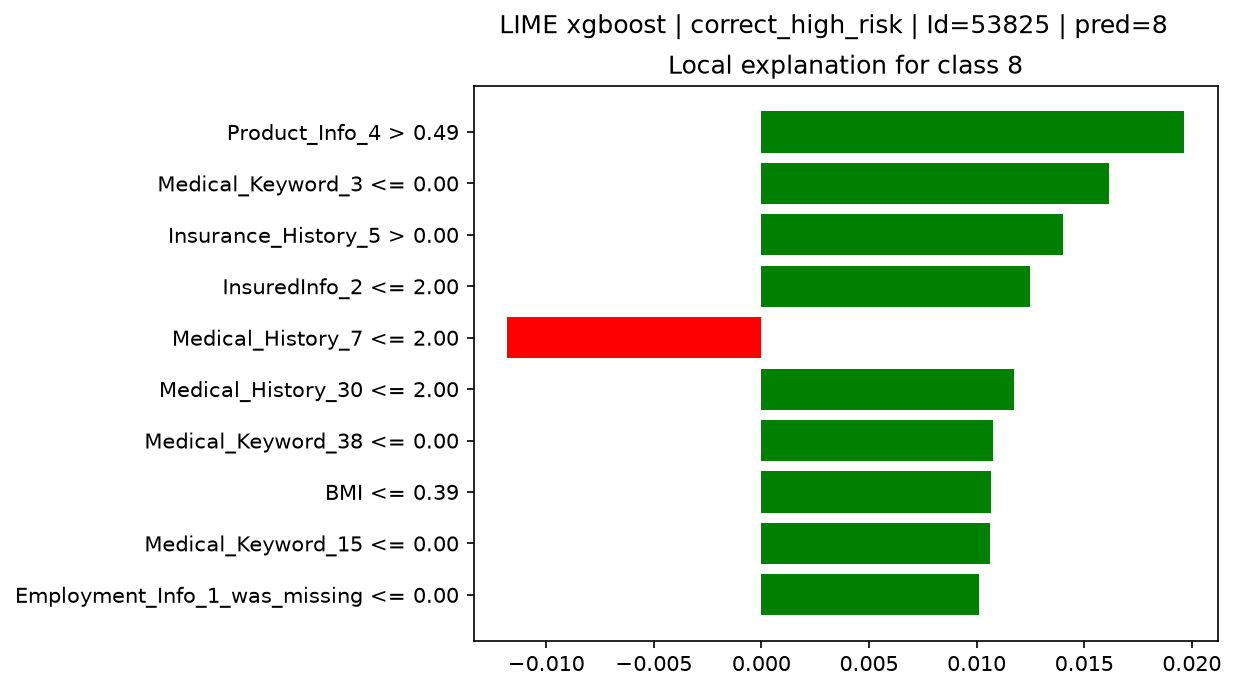

,feature,weight
0,Product_Info_4 > 0.49,0.019625
1,Medical_Keyword_3 <= 0.00,0.016150
2,Insurance_History_5 > 0.00,0.014027
3,InsuredInfo_2 <= 2.00,0.012466
4,Medical_History_7 <= 2.00,-0.011801
5,Medical_History_30 <= 2.00,0.011718
6,Medical_Keyword_38 <= 0.00,0.010781
7,BMI <= 0.39,0.010667
8,Medical_Keyword_15 <= 0.00,0.010641
9,Employment_Info_1_was_missing <= 0.00,0.010111


xgboost | case 1 (correct_low_risk) | pred=1


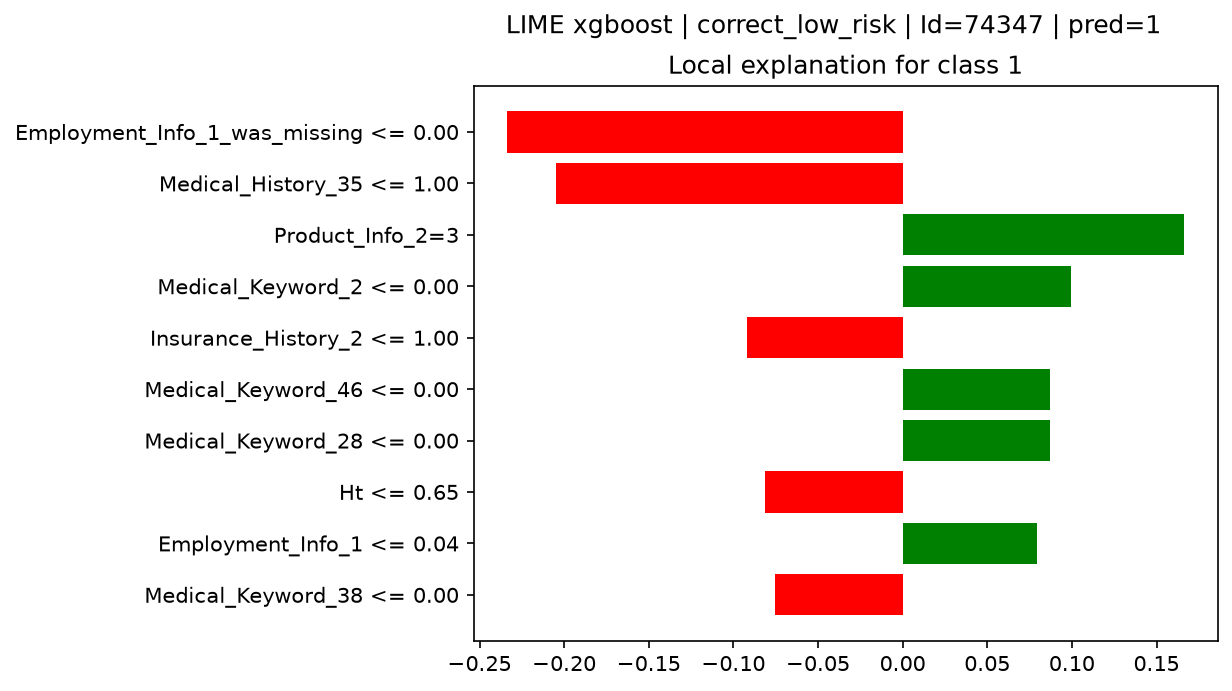

,feature,weight
0,Employment_Info_1_was_missing <= 0.00,-0.233515
1,Medical_History_35 <= 1.00,-0.204967
2,Product_Info_2=3,0.166106
3,Medical_Keyword_2 <= 0.00,0.099234
4,Insurance_History_2 <= 1.00,-0.091930
5,Medical_Keyword_46 <= 0.00,0.087174
6,Medical_Keyword_28 <= 0.00,0.086997
7,Ht <= 0.65,-0.081449
8,Employment_Info_1 <= 0.04,0.079479
9,Medical_Keyword_38 <= 0.00,-0.075452


xgboost | case 2 (misclassified_high_to_low) | pred=2


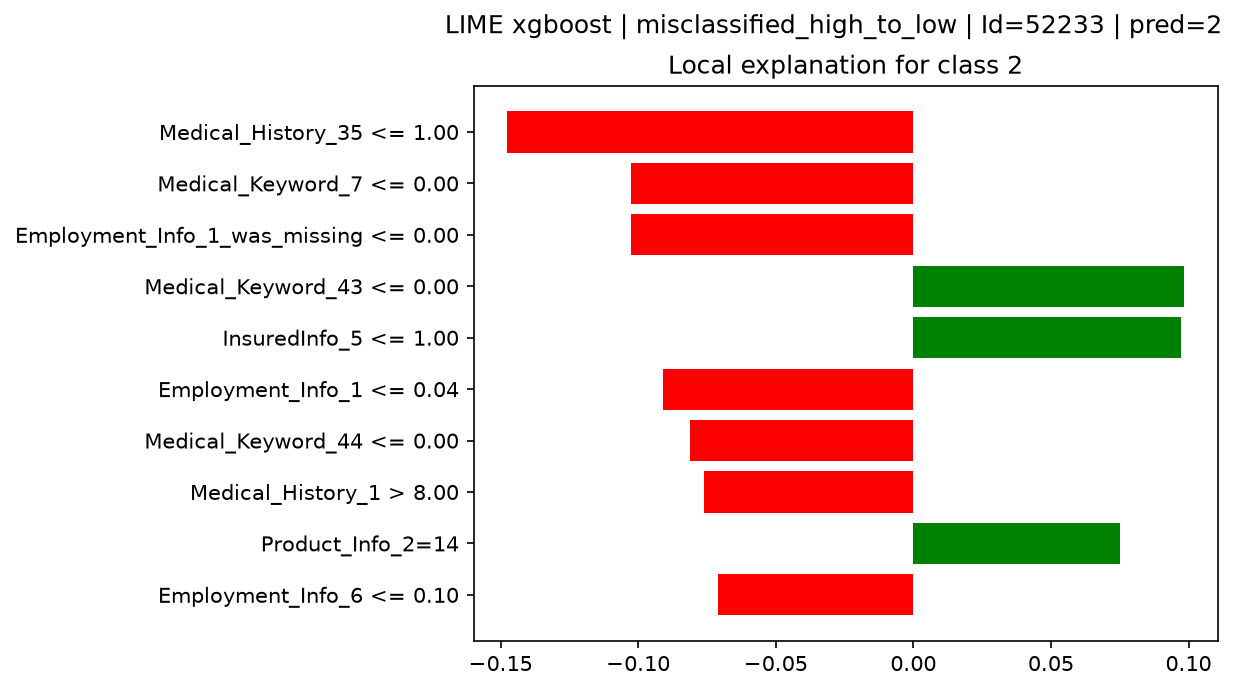

,feature,weight
0,Medical_History_35 <= 1.00,-0.147527
1,Medical_Keyword_7 <= 0.00,-0.102632
2,Employment_Info_1_was_missing <= 0.00,-0.102499
3,Medical_Keyword_43 <= 0.00,0.098278
4,InsuredInfo_5 <= 1.00,0.097109
5,Employment_Info_1 <= 0.04,-0.091077
6,Medical_Keyword_44 <= 0.00,-0.081209
7,Medical_History_1 > 8.00,-0.076086
8,Product_Info_2=14,0.075080
9,Employment_Info_6 <= 0.10,-0.070983


xgboost | case 3 (misclassified_low_to_high) | pred=5


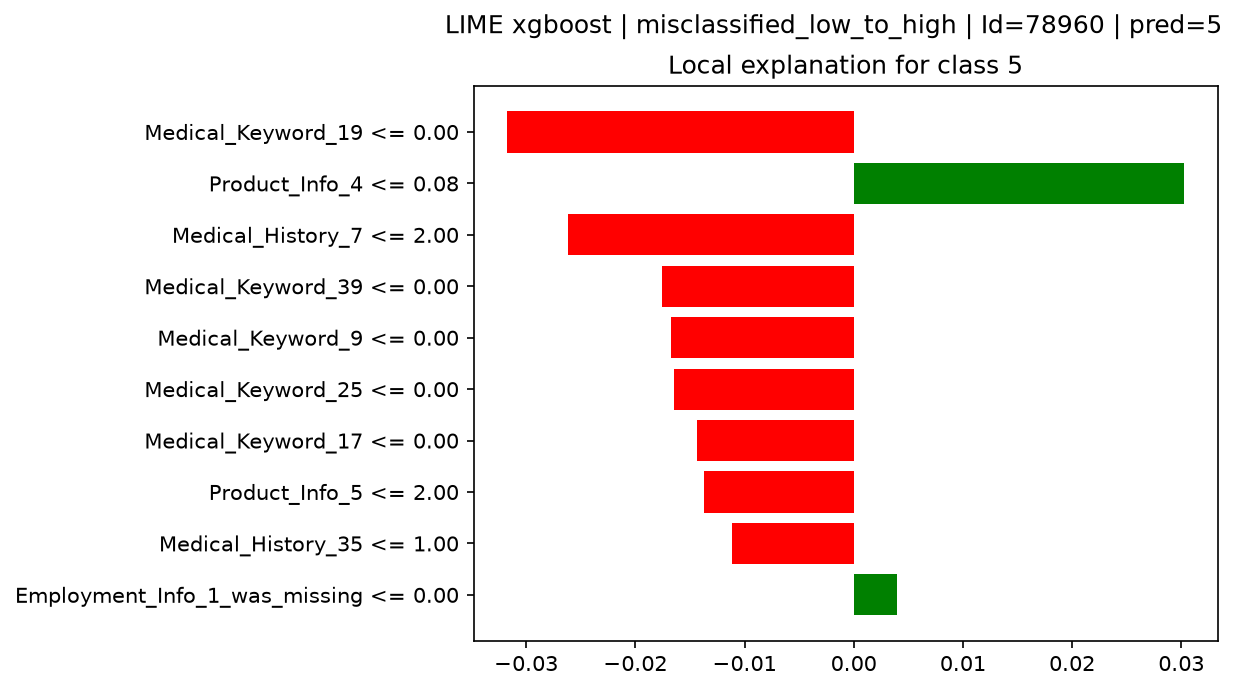

,feature,weight
0,Medical_Keyword_19 <= 0.00,-0.031715
1,Product_Info_4 <= 0.08,0.030225
2,Medical_History_7 <= 2.00,-0.026173
3,Medical_Keyword_39 <= 0.00,-0.017581
4,Medical_Keyword_9 <= 0.00,-0.016745
5,Medical_Keyword_25 <= 0.00,-0.016413
6,Medical_Keyword_17 <= 0.00,-0.014353
7,Product_Info_5 <= 2.00,-0.013727
8,Medical_History_35 <= 1.00,-0.011140
9,Employment_Info_1_was_missing <= 0.00,0.003959


xgboost | case 4 (rare_class_3_or_4) | pred=4


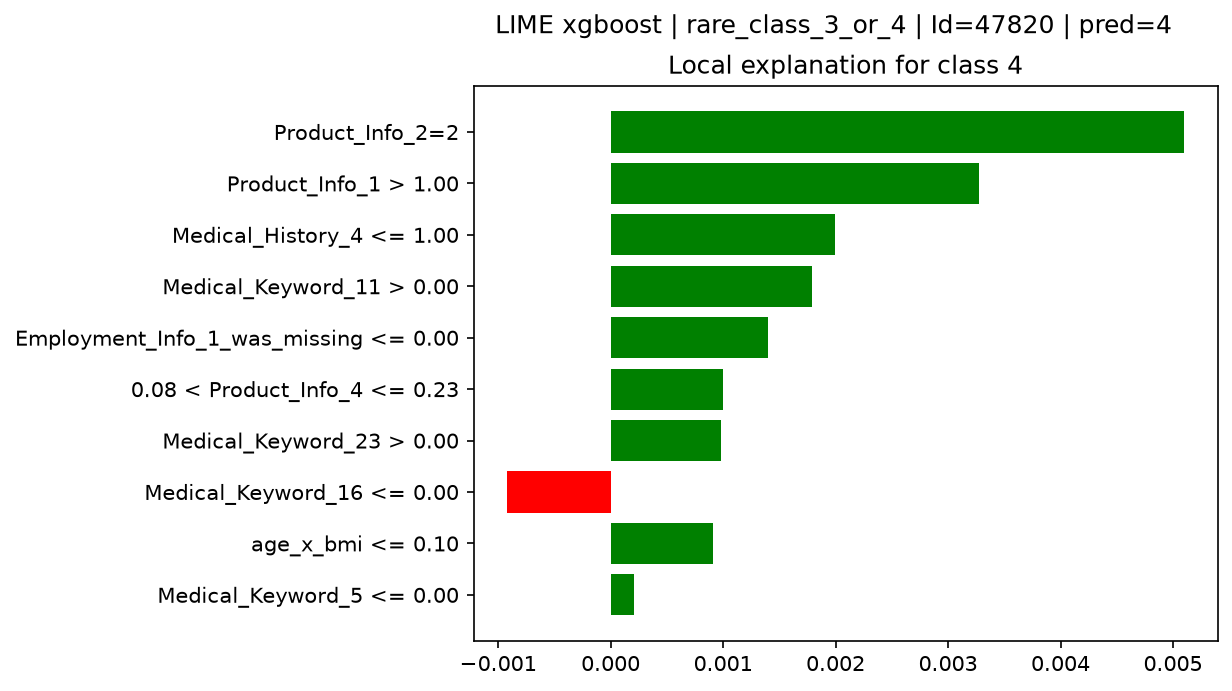

,feature,weight
0,Product_Info_2=2,0.005096
1,Product_Info_1 > 1.00,0.003279
2,Medical_History_4 <= 1.00,0.001998
3,Medical_Keyword_11 > 0.00,0.001793
4,Employment_Info_1_was_missing <= 0.00,0.001399
5,0.08 < Product_Info_4 <= 0.23,0.000998
6,Medical_Keyword_23 > 0.00,0.000977
7,Medical_Keyword_16 <= 0.00,-0.000918
8,age_x_bmi <= 0.10,0.000909
9,Medical_Keyword_5 <= 0.00,0.000212


xgboost | case 5 (typical_class_8) | pred=8


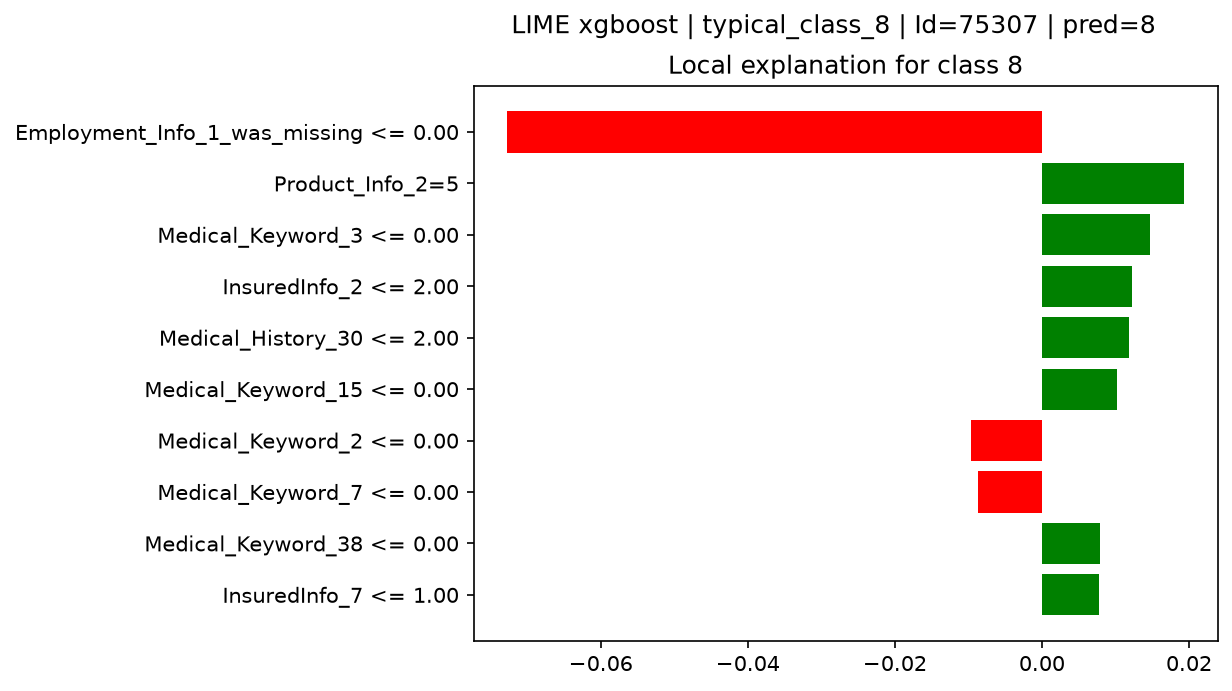

,feature,weight
0,Employment_Info_1_was_missing <= 0.00,-0.072693
1,Product_Info_2=5,0.019288
2,Medical_Keyword_3 <= 0.00,0.014743
3,InsuredInfo_2 <= 2.00,0.012275
4,Medical_History_30 <= 2.00,0.011895
5,Medical_Keyword_15 <= 0.00,0.010274
6,Medical_Keyword_2 <= 0.00,-0.009626
7,Medical_Keyword_7 <= 0.00,-0.008682
8,Medical_Keyword_38 <= 0.00,0.007940
9,InsuredInfo_7 <= 1.00,0.007821


logistic_regression | case 0 (correct_high_risk) | pred=8


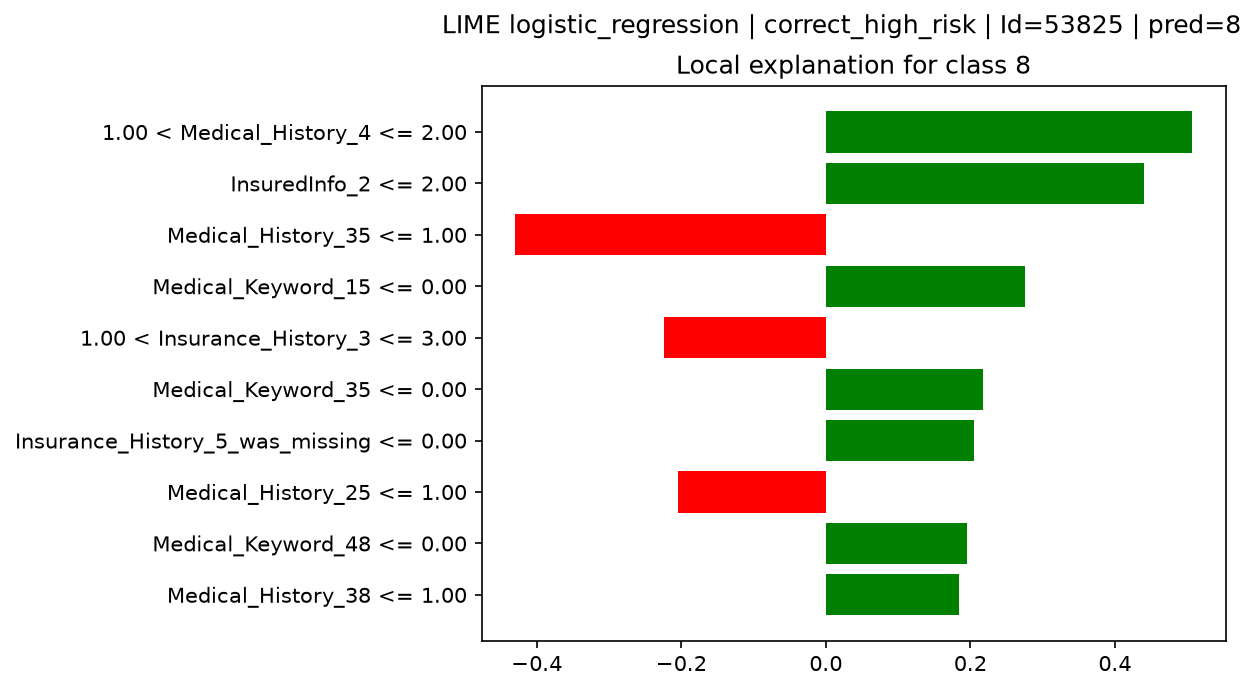

,feature,weight
0,1.00 < Medical_History_4 <= 2.00,0.506316
1,InsuredInfo_2 <= 2.00,0.439619
2,Medical_History_35 <= 1.00,-0.429509
3,Medical_Keyword_15 <= 0.00,0.275476
4,1.00 < Insurance_History_3 <= 3.00,-0.224439
5,Medical_Keyword_35 <= 0.00,0.217443
6,Insurance_History_5_was_missing <= 0.00,0.205258
7,Medical_History_25 <= 1.00,-0.205013
8,Medical_Keyword_48 <= 0.00,0.194701
9,Medical_History_38 <= 1.00,0.184325


logistic_regression | case 1 (correct_low_risk) | pred=1


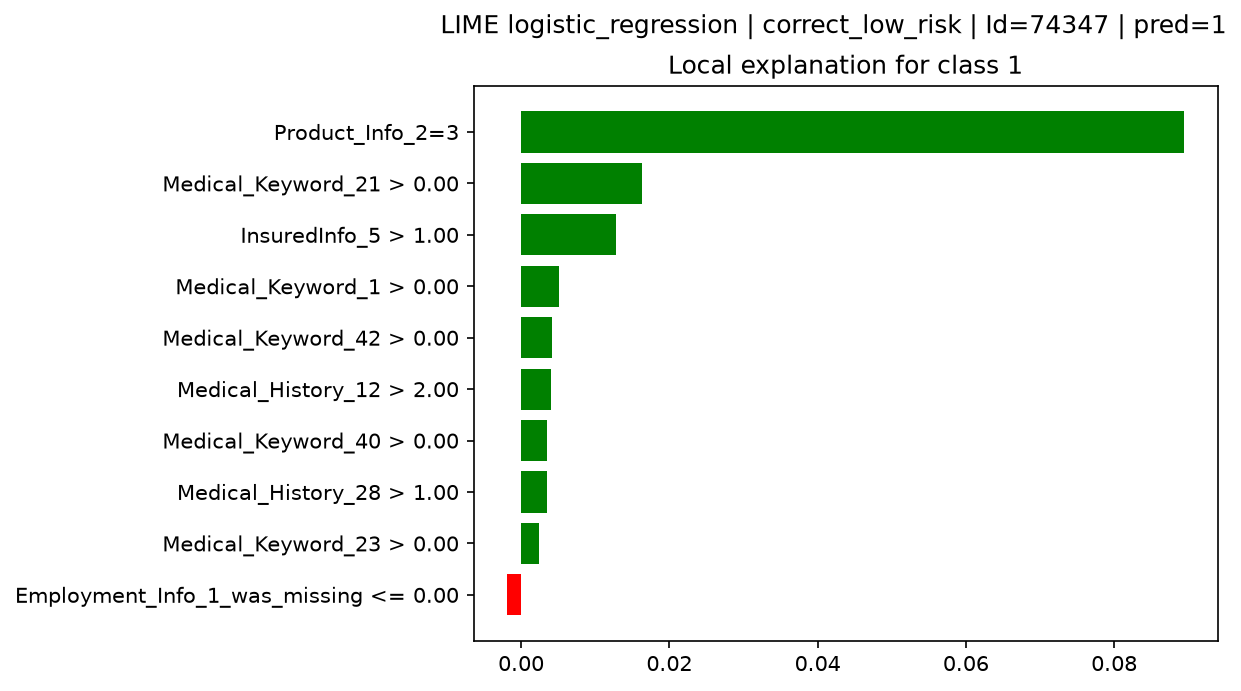

,feature,weight
0,Product_Info_2=3,0.089387
1,Medical_Keyword_21 > 0.00,0.016351
2,InsuredInfo_5 > 1.00,0.012806
3,Medical_Keyword_1 > 0.00,0.005163
4,Medical_Keyword_42 > 0.00,0.004140
5,Medical_History_12 > 2.00,0.004005
6,Medical_Keyword_40 > 0.00,0.003524
7,Medical_History_28 > 1.00,0.003463
8,Medical_Keyword_23 > 0.00,0.002382
9,Employment_Info_1_was_missing <= 0.00,-0.001849


In [6]:

lime = json.loads((WP4 / "lime_cases.json").read_text(encoding="utf-8"))
for entry in lime["cases"]:
    if entry["model"] != "xgboost" and not (
        entry["model"] == "logistic_regression" and entry["case_index"] < 2
    ):
        continue
    print(f"{entry['model']} | case {entry['case_index']} ({entry['label']}) | pred={entry['y_pred']}")
    display(Image(filename=str(WP4 / entry["image"])))
    display(pd.DataFrame(entry["weights"]))
